# Notebook 01 — Per-component panels

For each selected component, produce the standard set of cross-feature-type panels: sample-level scatter, cell-type loading bar, and per-omic loadings laid out by chromosome (RNA / methylation / H3K9ac ChIP / proteins).

These are the visual building blocks for every per-component figure in the manuscript. Choose a single component for a focused view, or sweep all 546 to dump panels to disk.

## Required Synapse files

Download from the Synapse sub-project (accession TBD). Place all files in a
single directory and set `DEPOSIT_DIR` below.

| File | Shape | Description |
|---|---|---|
| `samples_final.csv` | 546 × 276 | Component × sample loadings |
| `cell_type.csv` | 546 × 6 | Component × cell-type loadings (Ast, Oli, Inh, OPC, Exc, Mic) |
| `RNA.txt` | 25,098 × 546 | Gene × component loadings (PIP > 0.5 masked) |
| `meth.txt` | 51,798 × 546 | CpG × component loadings (PIP > 0.5 masked) |
| `chip.txt` | 26,384 × 546 | H3K9ac peak × component loadings (PIP > 0.5 masked) |
| `proteins.txt` | 5,230 × 546 | Protein × component loadings (PIP > 0.5 masked) |

## Required reference annotations

Bundled in `references/` (or downloaded yourself — see references/README.md).

| File | Description |
|---|---|
| `Homo_sapiens.GRCh38.100.txt` | Gene annotation (Ensembl 100) |
| `ROSMAP_arrayMethylation_metaData.tsv` | Illumina methylation array manifest |
| `H3K9acDomains.csv` | H3K9ac ChIP-seq peak coordinates (Klein et al.) |

Clinical metadata (`ROSMAP_clinical.csv`) is **not redistributed** — it is
controlled-access (request via the [AD Knowledge Portal DUC]
(https://adknowledgeportal.synapse.org/Data%20Access)). Notebooks that need
clinical variables document their dependency inline and degrade gracefully
when the file is absent.


## Setup

In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Add the repo root to sys.path so we can import the helper module.
sys.path.insert(0, "..")
import g_ros_release as gr

gr.apply_plot_style()


In [2]:
# Path configuration — edit these two paths to match your local layout.
# `DEPOSIT_DIR` is where you downloaded the Synapse files (syn3219045 sub-
# project, accession TBD on publication). `REFERENCES_DIR` is the bundled
# `references/` directory in this repo.

# DEPOSIT_DIR is auto-resolved between two common layouts:
#   1. `synapse/` inside the cloned repo (default — what end-users get when
#      they download the deposit into a `synapse/` folder at the repo root)
#   2. `synapse/` as a sibling of the repo (the local-prep layout used to
#      keep code and data physically separate during preparation)
# To override either default, set the env var G_ROS_DEPOSIT_DIR.
import os as _os
DEPOSIT_DIR = _os.environ.get("G_ROS_DEPOSIT_DIR", "../synapse")
if not _os.path.exists(_os.path.join(DEPOSIT_DIR, "samples_final.csv")):
    _fallback = "../../synapse"
    if _os.path.exists(_os.path.join(_fallback, "samples_final.csv")):
        DEPOSIT_DIR = _fallback
        print(f"[notebook] using sibling deposit layout: {DEPOSIT_DIR}")
REFERENCES_DIR = "../references"             # bundled with this repo

deposit = gr.load_deposit(DEPOSIT_DIR, REFERENCES_DIR, load_references=True)
print(f"Loaded {len(deposit.samples)} components × {deposit.samples.shape[1]} samples")


Loaded 546 components × 276 samples


## Configuration

In [3]:
# Choose which components to run. Defaults to the six headline components
# featured in the manuscript. To sweep all 546 components, replace with:
#     COMPONENTS = list(range(1, 547))
# To run a single component, e.g. just Component 351:
#     COMPONENTS = [351]
#
# Headline components and their manuscript role (also in gr.HEADLINE_COMPONENTS):
#   351 — Figure 2 (microglial immunometabolic program)
#     2 — Figure 3 (multi-omic regulatory features)
#    74 — Figure 4 (sex-differentiated programs)
#    87 — Figure 5 (astrocyte immune-modulation)
#   278 — Sup Fig S4 (female-biased OPC/precursor shift)
#   177 — Sup Fig S5 (microglial bioenergetic program)

COMPONENTS = [351, 2, 74, 87, 278, 177]

# Where to save figures. Set to None to display inline only.
SAVE_FIGURES_DIR = None  # e.g. "./out/panels"

if SAVE_FIGURES_DIR is not None:
    os.makedirs(SAVE_FIGURES_DIR, exist_ok=True)


## Optional: clinical metadata for sex overlay on the sample scatter

If `ROSMAP_clinical.csv` is in `REFERENCES_DIR`, the sample scatter colour-codes points by sex and sorts by age at death. Otherwise it falls back to a default plot.

In [4]:
clin_path = os.path.join(REFERENCES_DIR, 'ROSMAP_clinical.csv')
if os.path.exists(clin_path):
    clinical_df = pd.read_csv(clin_path, index_col=0)
    print(f'Loaded clinical metadata: {clinical_df.shape}')
else:
    clinical_df = None
    print('ROSMAP_clinical.csv not present — sample scatter will run without sex/age annotation.')


Loaded clinical metadata: (3584, 17)


## Per-component annotation joins

We pre-build the gene / methylation / ChIP annotation tables once, in the format expected by `gr.plot_loadings_by_chromosome`. These are reused across every component.

In [5]:
# Gene annotation (RNA + proteins): index by gene symbol, with chrom + chromStart
gene_annot = deposit.references['gene_annot']
gene_annot = gene_annot.assign(label=gene_annot['gene_name'])
gene_annot.index = gene_annot['gene_name']
rna_annot = gene_annot[['chrom', 'chromStart', 'label']]

# Methylation annotation: chr + position + composite label
meth_annot = deposit.references['meth_annot'].copy()
meth_annot['CHR'] = meth_annot['CHR'].astype(str)
meth_annot['label'] = meth_annot.apply(
    lambda r: f"{r.name}:{str(r['RefGene']).split(';')[0]}" if pd.notna(r.get('RefGene')) else r.name,
    axis=1,
)
meth_annot_sub = meth_annot[['CHR', 'MAPINFO', 'label']]

# ChIP annotation: chromosome + start + classification label
chip_annot = deposit.references['chip_annot'].copy()
chip_annot['Chr'] = chip_annot['Chr'].astype(str)
chip_annot['label'] = chip_annot.apply(
    lambda r: f"{r.name}:{r['Classification']}", axis=1,
)
chip_annot_sub = chip_annot[['Chr', 'Start', 'label']]

# Protein annotation: strip 'SYMBOL|UniProt' to SYMBOL, look up in gene_annot
protein_index = deposit.genes['proteins'].index
protein_annot = pd.DataFrame(index=protein_index)
protein_annot['symbol'] = [str(s).split('|')[0] for s in protein_index]
protein_annot = protein_annot.merge(
    gene_annot[['chrom', 'chromStart']],
    left_on='symbol', right_index=True, how='left',
)
protein_annot['label'] = protein_annot['symbol']
protein_annot_sub = protein_annot[['chrom', 'chromStart', 'label']].dropna()


## Helper — produce all panels for one component

In [6]:
def produce_panels(component_id: int, save_dir: str | None = None) -> None:
    """Produce sample scatter + cell-type bar + per-omic chromosome plots.

    Plots are shown inline. If `save_dir` is given, each panel is also
    saved as a PDF under `<save_dir>/<component_id>/<panel>.pdf`.
    """
    s = gr.component_summary(deposit, component_id)
    print(f"\n=== Component {component_id} — {s['manuscript_role']} ===")
    print(f"  top+={s['top_celltype_pos']}, top-={s['top_celltype_neg']}, "
          f"PIP-features RNA={s['n_features_RNA']} meth={s['n_features_meth']} "
          f"chip={s['n_features_chip']} proteins={s['n_features_proteins']}")

    if save_dir is not None:
        comp_dir = os.path.join(save_dir, str(component_id))
        os.makedirs(comp_dir, exist_ok=True)
    else:
        comp_dir = None

    # Sample scatter
    fig = plt.figure(figsize=(8, 4))
    ax = fig.add_subplot(111)
    gr.plot_sample_scatter(deposit, component_id, sample_metadata=clinical_df, ax=ax)
    if comp_dir is not None:
        plt.savefig(os.path.join(comp_dir, 'samples.pdf'), bbox_inches='tight')
    plt.show()

    # Cell-type bar
    fig, ax = plt.subplots(figsize=(6, 4))
    gr.plot_celltype_bar(deposit, component_id, ax=ax)
    plt.tight_layout()
    if comp_dir is not None:
        plt.savefig(os.path.join(comp_dir, 'cell_type.pdf'), bbox_inches='tight')
    plt.show()

    # Per-omic chromosome scatters (skip if no PIP-significant features)
    omic_specs = [
        ('RNA',      rna_annot,         'chrom',      'chromStart', 'label'),
        ('meth',     meth_annot_sub,    'CHR',        'MAPINFO',    'label'),
        ('chip',     chip_annot_sub,    'Chr',        'Start',      'label'),
        ('proteins', protein_annot_sub, 'chrom',      'chromStart', 'label'),
    ]
    for omic, annot, chrom_col, pos_col, label_col in omic_specs:
        n_feats = int(deposit.genes[omic][component_id].notna().sum())
        if n_feats == 0:
            print(f"  [{omic}] no PIP-significant features for component {component_id}; skipping.")
            continue
        fig, ax = plt.subplots(figsize=(12, 4))
        gr.plot_loadings_by_chromosome(
            deposit, component_id, omic=omic,
            feature_annot=annot,
            chrom_col=chrom_col, pos_col=pos_col, label_col=label_col,
            ax=ax,
        )
        plt.tight_layout()
        if comp_dir is not None:
            plt.savefig(os.path.join(comp_dir, f'{omic}.pdf'), bbox_inches='tight')
        plt.show()


## Run on selected components

When `COMPONENTS` is large (e.g., a full sweep of 1..546), set `SAVE_FIGURES_DIR` to a directory and consider running this loop from the command line instead — running 546 × ~6 plots inline in a notebook is slow and memory-hungry.


=== Component 351 — Figure 2 — microglial immunometabolic program ===
  top+=Oli, top-=Mic, PIP-features RNA=707 meth=7 chip=584 proteins=315


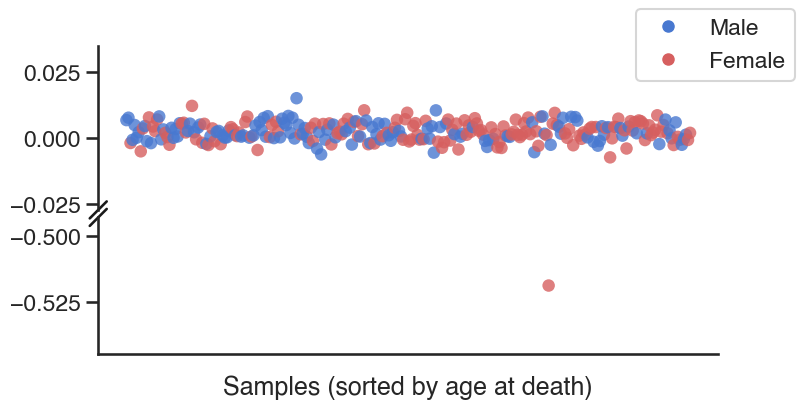

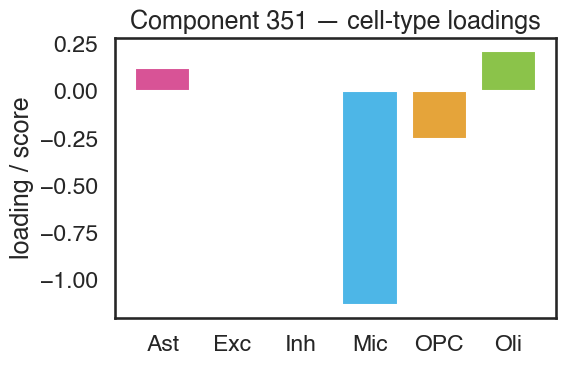

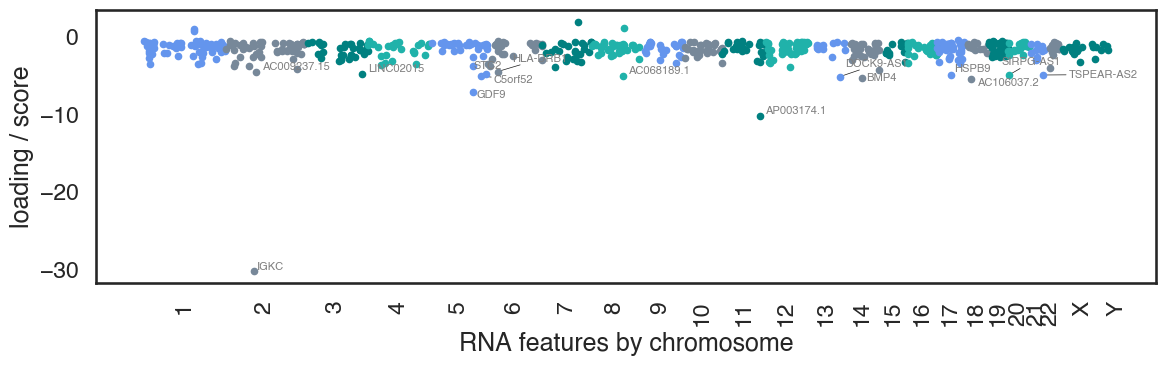

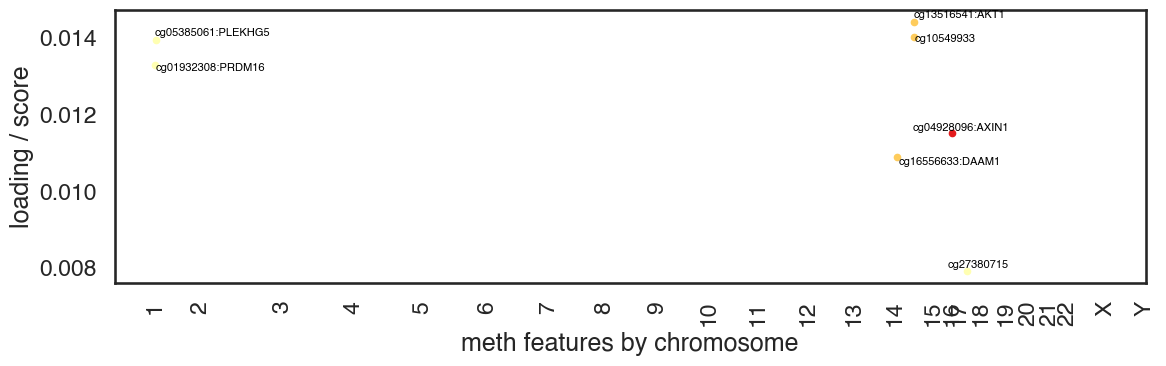

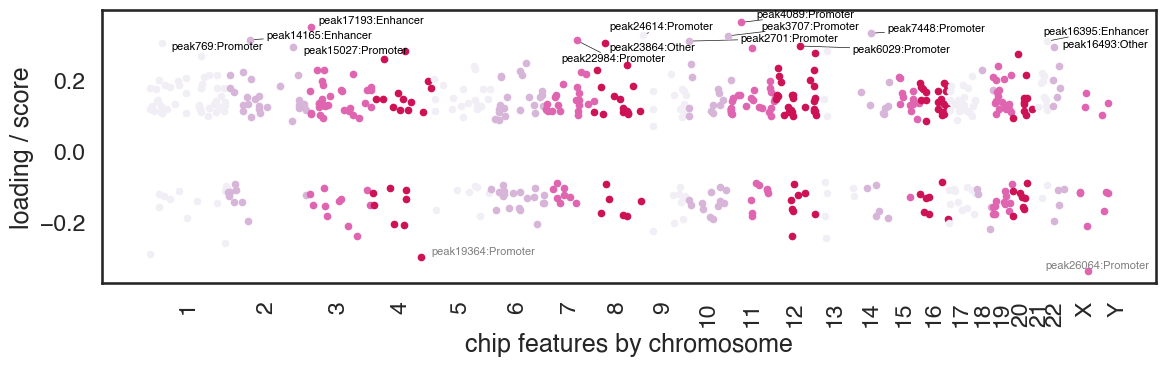

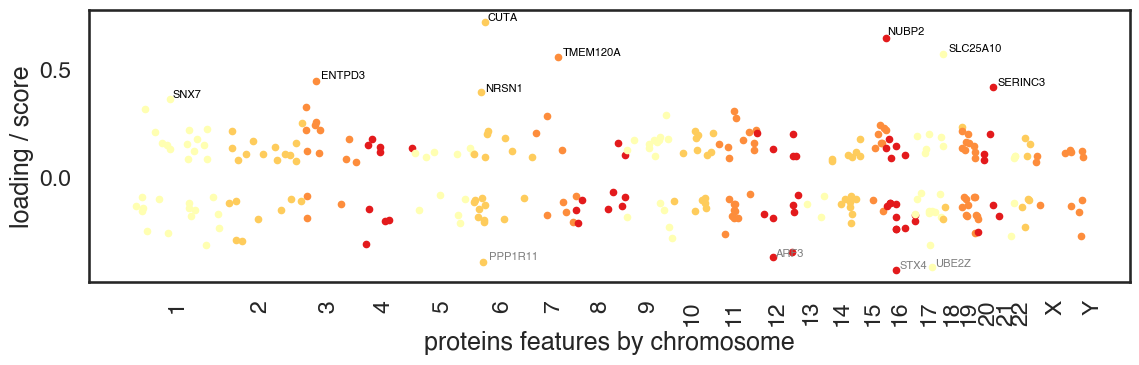


=== Component 2 — Figure 3 — multi-omic regulatory features ===
  top+=Mic, top-=Ast, PIP-features RNA=277 meth=6 chip=7 proteins=0


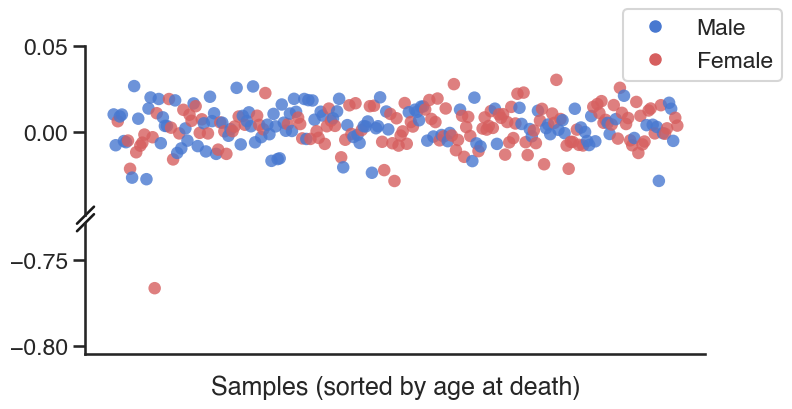

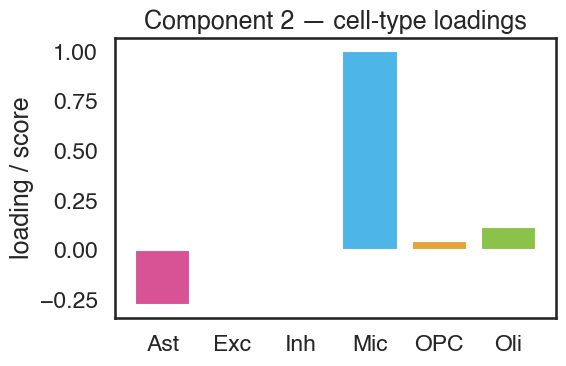

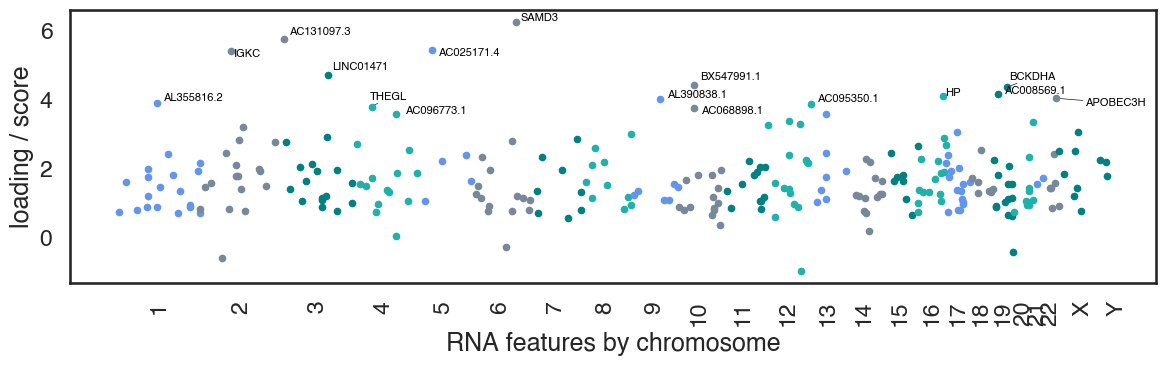

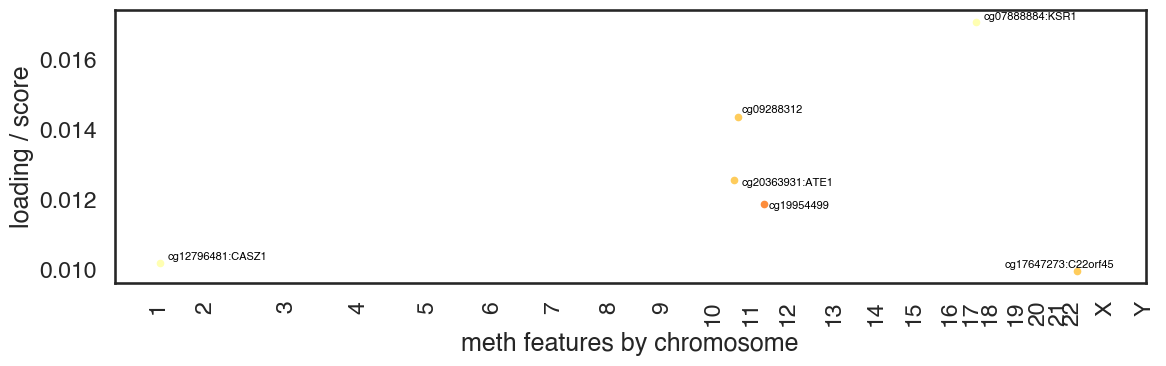

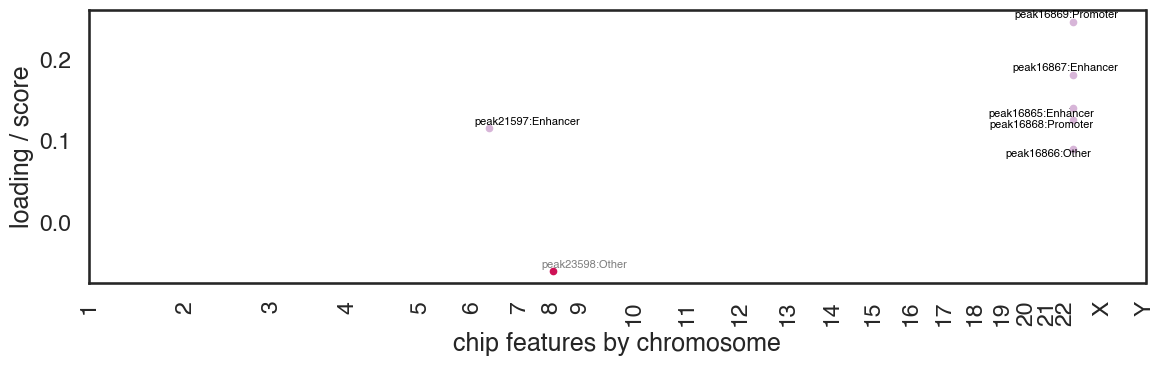

  [proteins] no PIP-significant features for component 2; skipping.

=== Component 74 — Figure 4 — sex-differentiated programs ===
  top+=Exc, top-=Oli, PIP-features RNA=161 meth=3435 chip=676 proteins=0


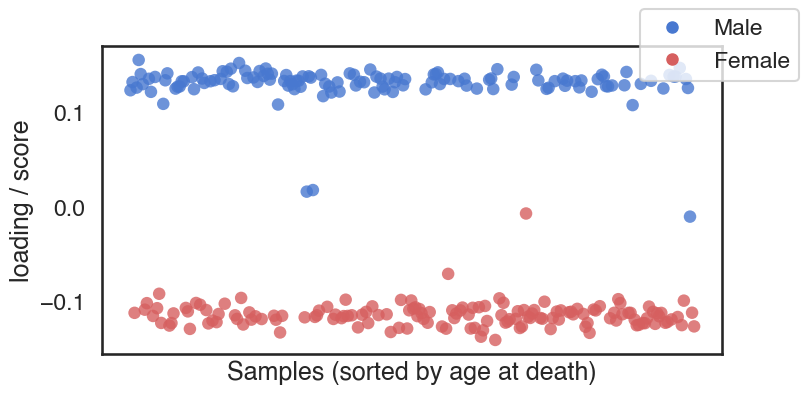

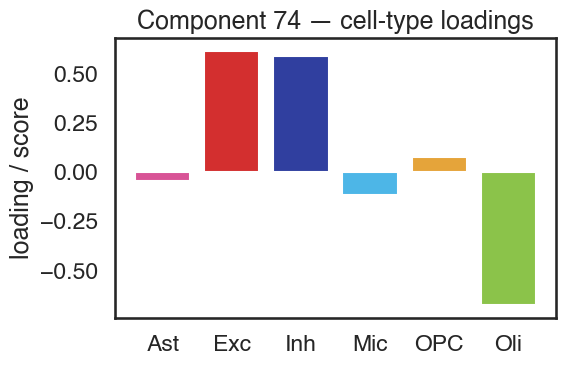

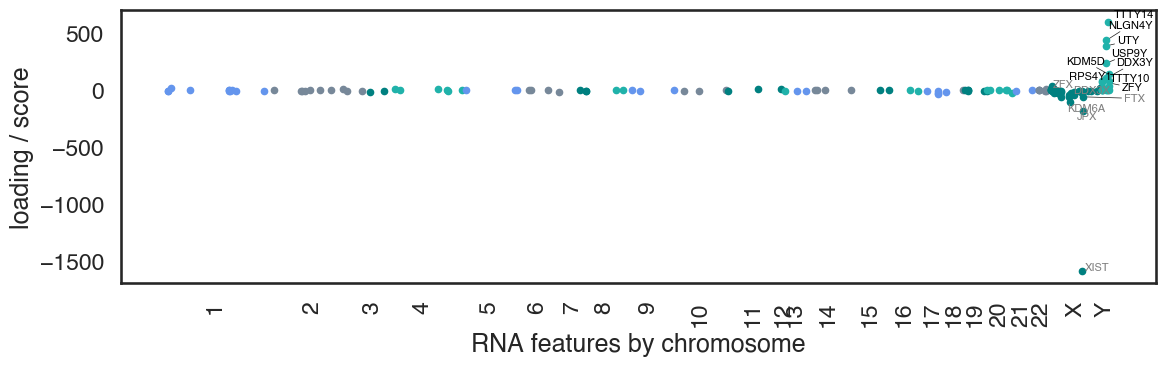

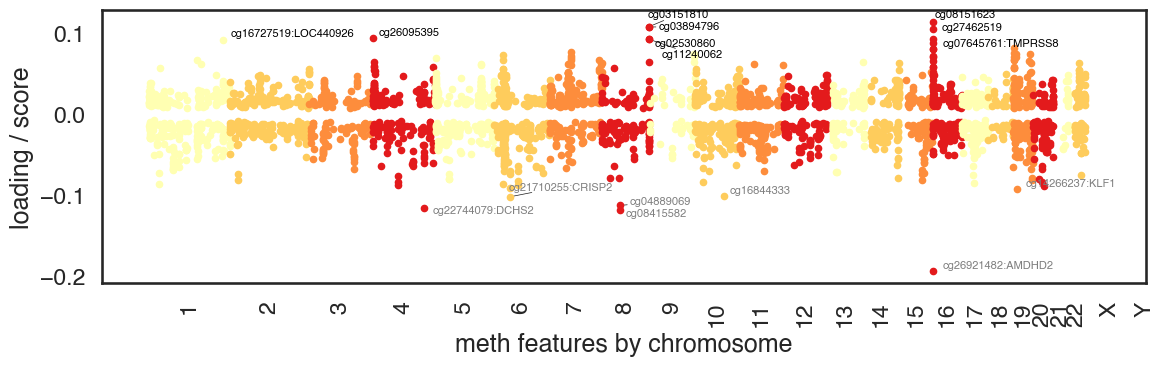

0 [-0.71969849  0.45898201]
7 [ 0.02420755 -0.30191221]


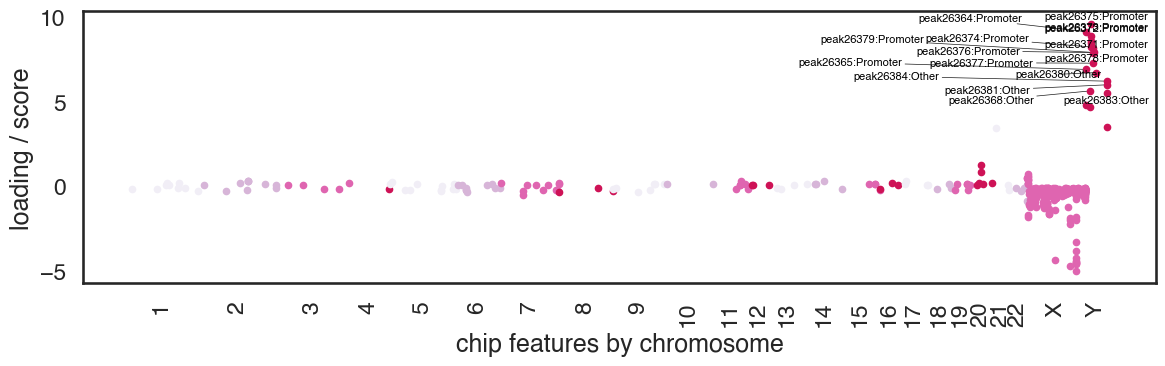

  [proteins] no PIP-significant features for component 74; skipping.

=== Component 87 — Figure 5 — astrocyte immune-modulation / epigenetic-reprogramming ===
  top+=Ast, top-=OPC, PIP-features RNA=255 meth=2 chip=2 proteins=0


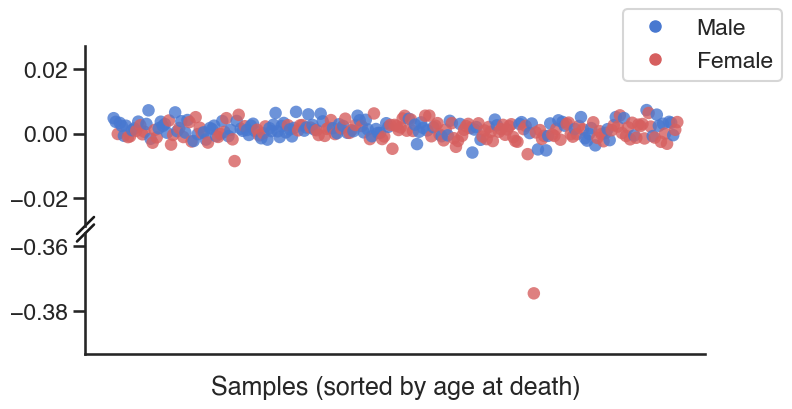

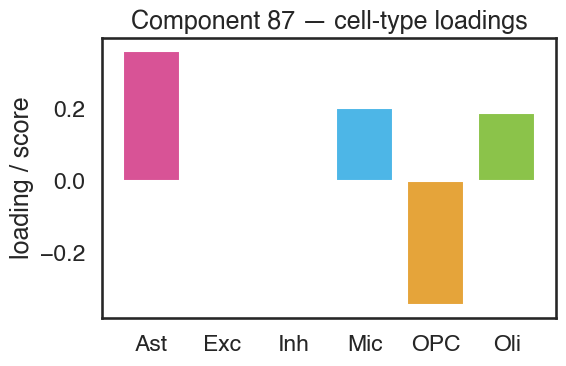

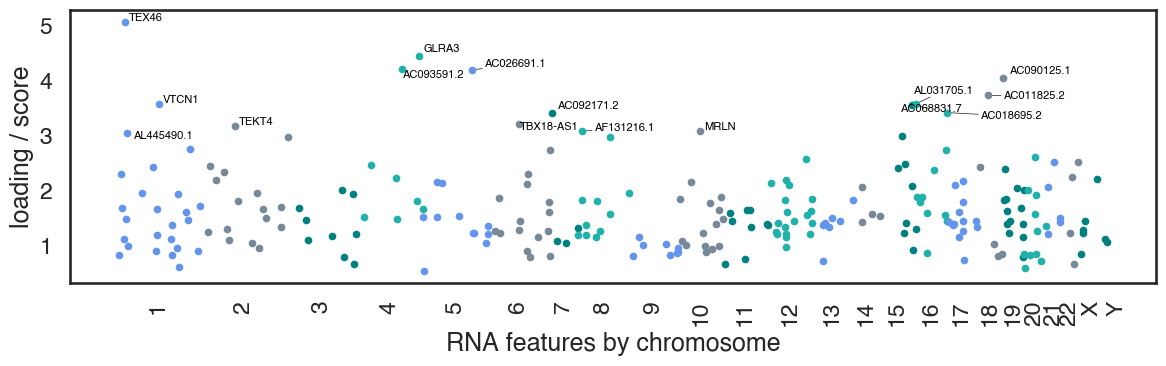

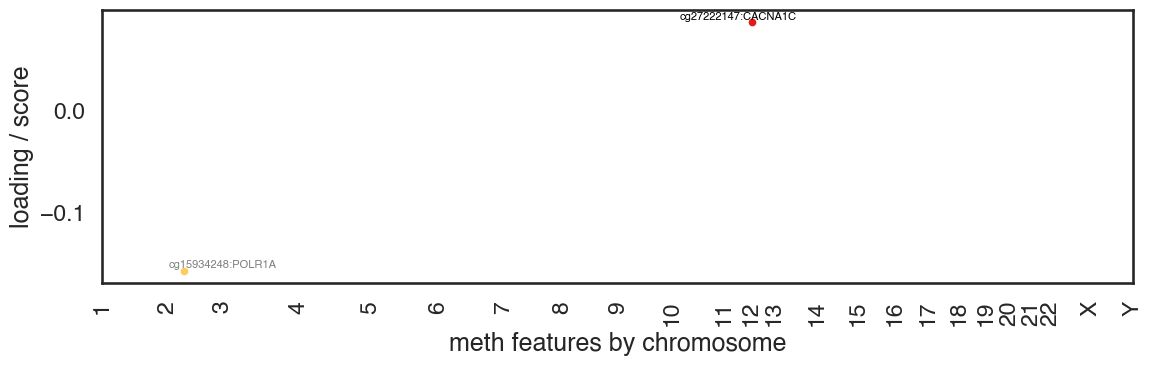

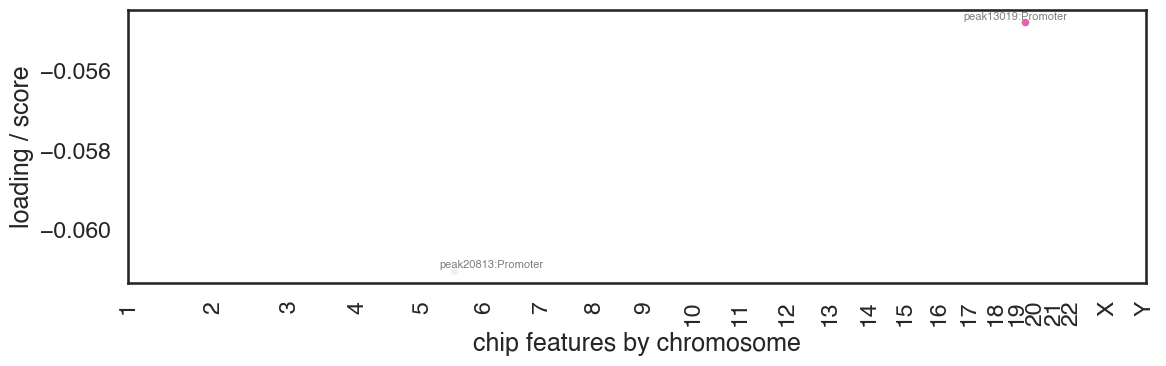

  [proteins] no PIP-significant features for component 87; skipping.

=== Component 278 — Supplementary Figure S4 — female-biased OPC/precursor shift ===
  top+=OPC, top-=Oli, PIP-features RNA=1114 meth=0 chip=0 proteins=0


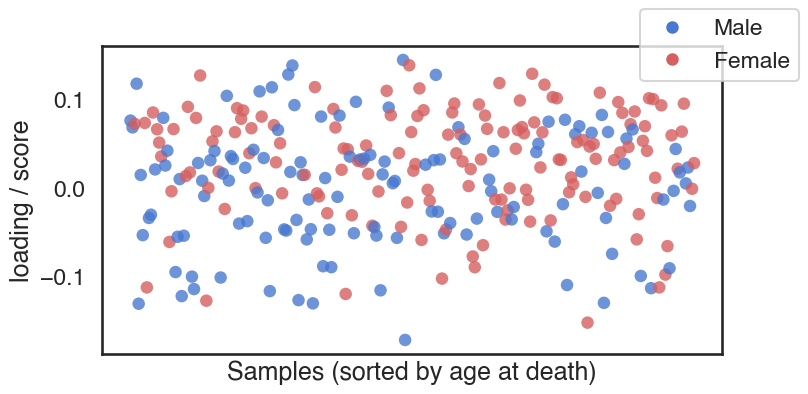

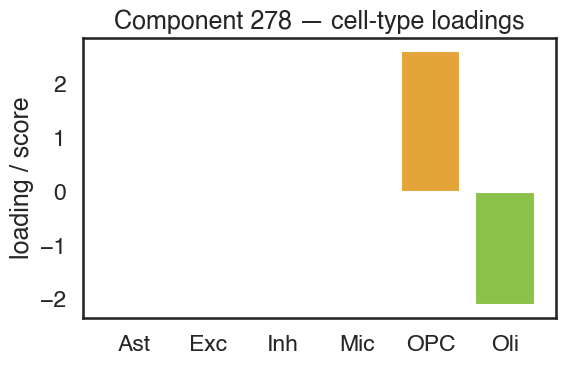

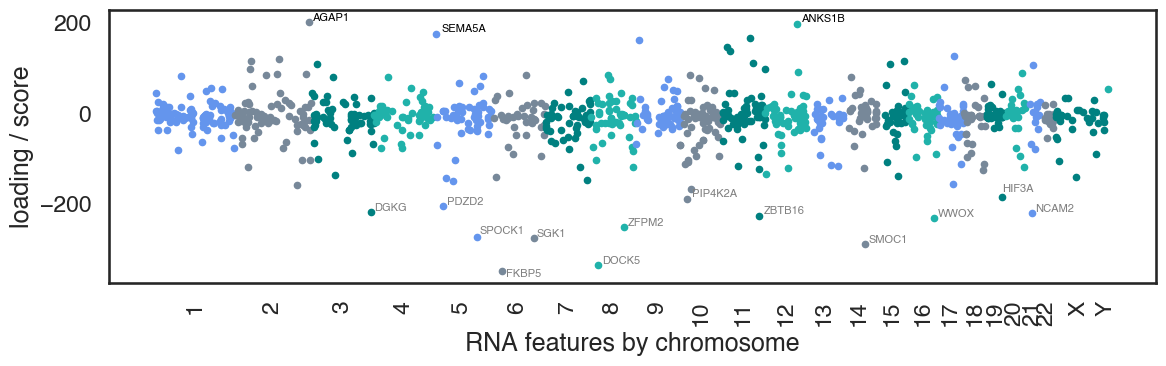

  [meth] no PIP-significant features for component 278; skipping.
  [chip] no PIP-significant features for component 278; skipping.
  [proteins] no PIP-significant features for component 278; skipping.

=== Component 177 — Supplementary Figure S5 — microglial bioenergetic program ===
  top+=Ast, top-=Mic, PIP-features RNA=155 meth=8 chip=0 proteins=1


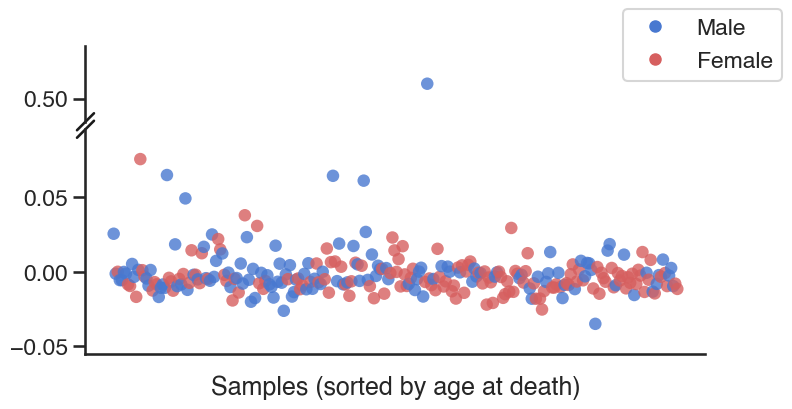

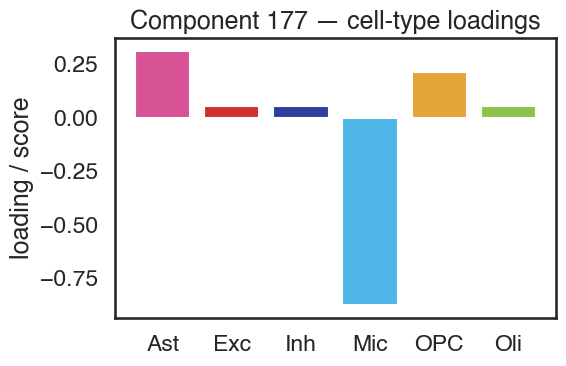

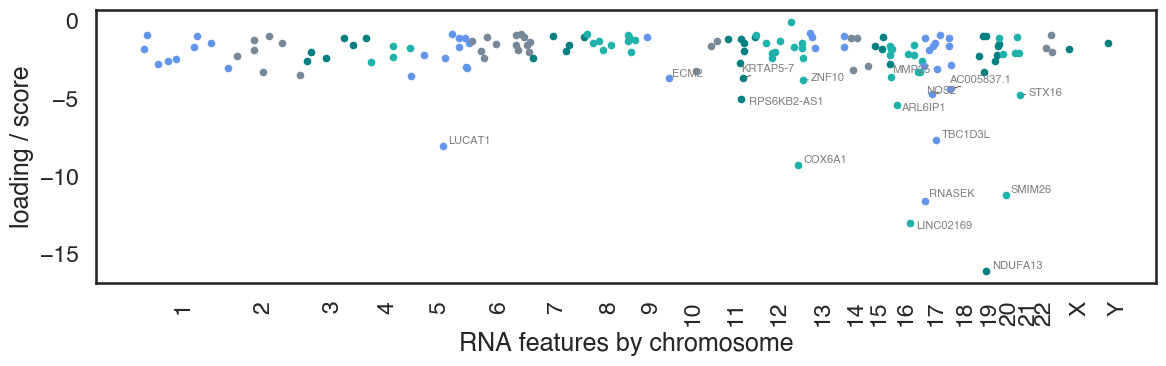

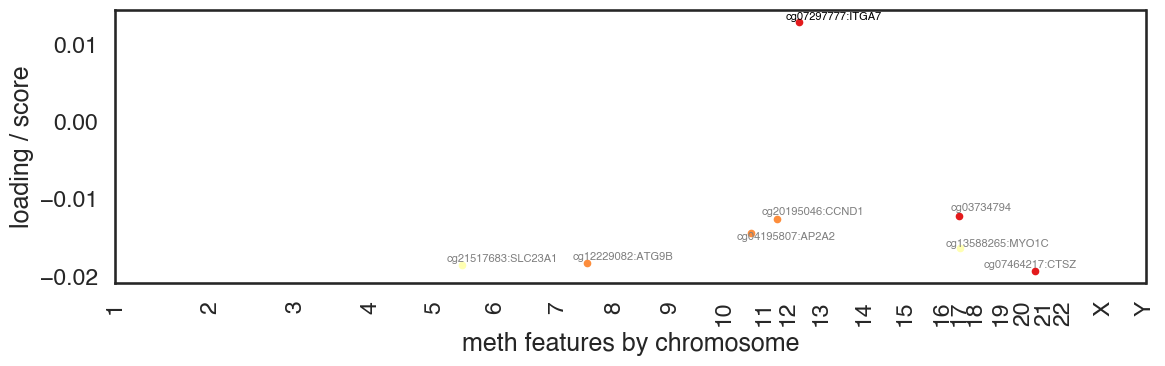

  [chip] no PIP-significant features for component 177; skipping.


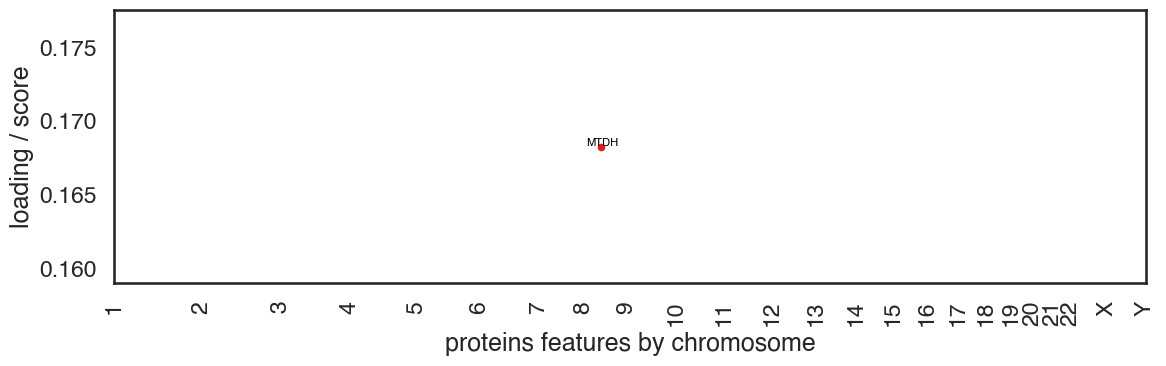

In [7]:
for cid in COMPONENTS:
    if not deposit.has_component(cid):
        print(f'Component {cid} not in deposit; skipping.')
        continue
    produce_panels(cid, save_dir=SAVE_FIGURES_DIR)


## Notes

**Sign convention.** SDA components are sign-arbitrary — the sign of a component's loadings can be flipped without changing the decomposition. The manuscript figures may display loadings with the sign flipped relative to the deposit values for narrative clarity (e.g., to make the 'microglial' pole appear positive). If you want to compare a notebook panel to a manuscript figure, check the cell-type bar: if the manuscript's top-driver matches this notebook's `top_celltype_neg` rather than `top_celltype_pos`, the published figure is sign-flipped.

**Reproducing manuscript figures.** Each manuscript figure combines panels for one specific component (Fig 2 → 351, Fig 3 → 2, Fig 4 → 74, Fig 5 → 87, Sup S4 → 278, Sup S5 → 177). After running this notebook for the relevant component, the saved PDFs (or inline outputs) are the figure's per-component panels.